# DATA 255 Lab 1 - ImageNet20 Classification from Scratch

**Objective:** Train a custom CNN from scratch for ImageNet-20 classification and export to ONNX format.

**Requirements:**
- Input: 240×240×3 RGB images
- Output: 20 classes
- No pretrained weights allowed
- Target: 60%+ validation accuracy

**Output Files Generated:**
1. `best_model.pth` - Best trained model weights
2. `model_imagenet20.onnx` - ONNX exported model
3. `calibration_images.zip` - Calibration images for MXQ conversion
4. `npu_valid.py` - NPU validation script
5. `onnx__mxq_conversion.py` - ONNX to MXQ conversion script

## Step 1: Mount Google Drive & Setup Environment

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set your Google Drive paths
# Change this to your folder path containing the dataset files
DRIVE_DATA_PATH = '/content/drive/MyDrive/DL Lab1'
OUTPUT_PATH = '/content/drive/MyDrive/outputs_lab1'

# Create output directory
import os
os.makedirs(OUTPUT_PATH, exist_ok=True)
print(f"Data path: {DRIVE_DATA_PATH}")
print(f"Output path: {OUTPUT_PATH}")

Data path: /content/drive/MyDrive/DL Lab1
Output path: /content/drive/MyDrive/outputs_lab1


In [ ]:
# Install required packages
!pip install onnx onnxruntime -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.5/17.5 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.1/17.1 MB 73.4 MB/s eta 0:00:00


In [ ]:
# Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import numpy as np
from PIL import Image
import os
import zipfile
import shutil
from tqdm import tqdm
import matplotlib.pyplot as plt
import random

# Set seeds for reproducibility
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: Tesla T4


## Step 2: Extract Dataset

In [19]:
# Extract datasets
DATA_DIR = '/content/data'

# Create directories
os.makedirs(DATA_DIR, exist_ok=True)

# Extract training data
train_zip = os.path.join(DRIVE_DATA_PATH, 'imagenet_train20.zip')
val_zip = os.path.join(DRIVE_DATA_PATH, 'imagenet_val20.zip')

print("Extracting training data...")
with zipfile.ZipFile(train_zip, 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Extracting validation data...")
with zipfile.ZipFile(val_zip, 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

print("Extraction complete!")

# Detect the actual extracted structure
print("\nDetecting extracted structure...")
for item in os.listdir(DATA_DIR):
    item_path = os.path.join(DATA_DIR, item)
    if os.path.isdir(item_path):
        sub_items = os.listdir(item_path)[:3]
        print(f"  {item}/ -> {sub_items}...")
    else:
        print(f"  {item}")

# Find where images actually are (could be nested in train/val folders or class folders)
def find_image_root(base_dir):
    """Find the root directory where images are stored"""
    # Check if images are directly in base_dir with class subfolders
    for item in os.listdir(base_dir):
        item_path = os.path.join(base_dir, item)
        if os.path.isdir(item_path):
            # Check if this folder contains images
            for f in os.listdir(item_path)[:5]:
                if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                    return base_dir
            # Check one level deeper
            for sub in os.listdir(item_path)[:3]:
                sub_path = os.path.join(item_path, sub)
                if os.path.isdir(sub_path):
                    for f in os.listdir(sub_path)[:5]:
                        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                            return item_path
    return base_dir

TRAIN_ROOT = find_image_root(DATA_DIR)
print(f"\nImage root detected: {TRAIN_ROOT}")

Extracting training data...
Extracting validation data...
Extraction complete!

Detecting extracted structure...
  imagenet_val20/ -> ['n02006656_15628.JPEG', 'n01737021_8459.JPEG', 'n03016953_2959.JPEG']...
  imagenet_train20a/ -> ['n03938244', 'n03721384', 'n03804744']...

Image root detected: /content/data


In [ ]:
# Check extracted directory structure
!ls -la /content/data/

total 52
drwxr-xr-x  4 root root  4096 Feb 27 19:57 .
drwxr-xr-x  1 root root  4096 Feb 27 19:56 ..
drwxr-xr-x 22 root root  4096 Feb 27 19:57 imagenet_train20a
drwxr-xr-x  2 root root 36864 Feb 27 19:57 imagenet_val20


In [21]:
# Parse label files to get class mappings
train_txt = os.path.join(DRIVE_DATA_PATH, 'imagenet_train20.txt')
val_txt = os.path.join(DRIVE_DATA_PATH, 'imagenet_val20.txt')

def parse_label_file(filepath):
    """Parse label file with format: path label"""
    image_labels = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if line:
                parts = line.rsplit(' ', 1)  # Split from right to handle paths with spaces
                if len(parts) == 2:
                    path, label = parts
                    # Strip any whitespace from path!
                    path = path.strip()
                    image_labels.append((path, int(label)))
    return image_labels

train_labels = parse_label_file(train_txt)
val_labels = parse_label_file(val_txt)

print(f"Training samples: {len(train_labels)}")
print(f"Validation samples: {len(val_labels)}")
print(f"\nSample entries from txt file:")
print(f"Train: {repr(train_labels[0])}")  # repr to see any hidden characters
print(f"Val: {repr(val_labels[0])}")

# Build search directories - include ALL subdirectories
search_dirs = [DATA_DIR]
for item in os.listdir(DATA_DIR):
    item_path = os.path.join(DATA_DIR, item)
    if os.path.isdir(item_path):
        search_dirs.append(item_path)
        # Also add class subfolders (n01234567, etc.)
        for sub in os.listdir(item_path):
            sub_path = os.path.join(item_path, sub)
            if os.path.isdir(sub_path):
                search_dirs.append(sub_path)

print(f"\nSearch directories: {len(search_dirs)} dirs")
print(f"First few: {search_dirs[:5]}")

# Function to find images - simpler approach
def find_image_path(filename, search_dirs):
    """Search for an image file in directories"""
    filename = filename.strip()  # Remove any whitespace
    base_name = os.path.basename(filename)

    # Extract class prefix (e.g., n01737021 from n01737021_10059.JPEG)
    class_prefix = base_name.split('_')[0] if '_' in base_name else None

    for search_dir in search_dirs:
        # Direct match
        direct = os.path.join(search_dir, filename)
        if os.path.exists(direct):
            return direct

        # Just base filename
        simple = os.path.join(search_dir, base_name)
        if os.path.exists(simple):
            return simple

        # Check if search_dir ends with class prefix
        if class_prefix and search_dir.endswith(class_prefix):
            in_class = os.path.join(search_dir, base_name)
            if os.path.exists(in_class):
                return in_class

    return None

# Verify we can find images
test_path = find_image_path(train_labels[0][0], search_dirs)
print(f"\nTest image: {train_labels[0][0]}")
print(f"Found path: {test_path}")
print(f"Exists: {test_path is not None}")

# Also test a few more
found_count = 0
for i in range(min(10, len(train_labels))):
    if find_image_path(train_labels[i][0], search_dirs):
        found_count += 1
print(f"Found {found_count}/10 test images")

Training samples: 6000
Validation samples: 1000

Sample entries from txt file:
Train: ('n01737021_10059.JPEG', 0)
Val: ('n04346328_14853.JPEG', 19)

Search directories: 23 dirs
First few: ['/content/data', '/content/data/imagenet_val20', '/content/data/imagenet_train20a', '/content/data/imagenet_train20a/n03938244', '/content/data/imagenet_train20a/n03721384']

Test image: n01737021_10059.JPEG
Found path: /content/data/imagenet_train20a/n01737021/n01737021_10059.JPEG
Exists: True
Found 10/10 test images


In [ ]:
# Count classes
train_class_counts = {}
for _, label in train_labels:
    train_class_counts[label] = train_class_counts.get(label, 0) + 1

print(f"Number of classes: {len(train_class_counts)}")
print(f"Images per class (train): {list(train_class_counts.values())[:5]}...")

Number of classes: 20
Images per class (train): [300, 300, 300, 300, 300]...


## Step 3: Create Custom Dataset Class

In [22]:
class ImageNet20Dataset(Dataset):
    """Custom Dataset for ImageNet-20 subset"""

    def __init__(self, image_labels, search_dirs, transform=None):
        """
        Args:
            image_labels: List of (image_path, label) tuples
            search_dirs: List of directories to search for images
            transform: Optional transform to apply
        """
        self.image_labels = image_labels
        self.search_dirs = search_dirs
        self.transform = transform

        # Pre-build the path cache for faster loading
        print("Building image path cache...")
        self.path_cache = {}
        found = 0
        for img_path, _ in tqdm(image_labels, desc="Caching paths"):
            full_path = self._find_image(img_path)
            if full_path:
                self.path_cache[img_path] = full_path
                found += 1
        print(f"Found {found}/{len(image_labels)} images")

    def _find_image(self, filename):
        """Find image in search directories"""
        base_name = os.path.basename(filename)

        for search_dir in self.search_dirs:
            # Direct path
            direct = os.path.join(search_dir, filename)
            if os.path.exists(direct):
                return direct

            # Just filename
            simple = os.path.join(search_dir, base_name)
            if os.path.exists(simple):
                return simple

            # Search in class subdirectories
            if os.path.isdir(search_dir):
                for subdir in os.listdir(search_dir):
                    subdir_path = os.path.join(search_dir, subdir)
                    if os.path.isdir(subdir_path):
                        in_subdir = os.path.join(subdir_path, base_name)
                        if os.path.exists(in_subdir):
                            return in_subdir
        return None

    def __len__(self):
        return len(self.image_labels)

    def __getitem__(self, idx):
        img_path, label = self.image_labels[idx]

        # Get cached path
        full_path = self.path_cache.get(img_path)

        # Load image
        if full_path and os.path.exists(full_path):
            try:
                image = Image.open(full_path).convert('RGB')
            except Exception as e:
                # Return a random noise image if loading fails
                image = Image.new('RGB', (240, 240), (128, 128, 128))
        else:
            # Return a gray image if path not found
            image = Image.new('RGB', (240, 240), (128, 128, 128))

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
# Define transforms - INPUT SIZE IS 240x240 as per lab requirements
IMG_SIZE = 240

# ImageNet normalization values
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Training transforms with augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE + 20, IMG_SIZE + 20)),  # Resize slightly larger for random crop
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.1),
])

# Validation transforms (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

In [23]:
# Create datasets using the search directories
train_dataset = ImageNet20Dataset(train_labels, search_dirs, transform=train_transform)
val_dataset = ImageNet20Dataset(val_labels, search_dirs, transform=val_transform)

# Create dataloaders
BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"\nTraining batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Building image path cache...


Caching paths: 100%|██████████| 6000/6000 [00:26<00:00, 225.66it/s]


Found 6000/6000 images
Building image path cache...


Caching paths: 100%|██████████| 1000/1000 [00:00<00:00, 23453.49it/s]

Found 1000/1000 images

Training batches: 188
Validation batches: 32


Error loading /content/data/n03476684_4120.JPEG: [Errno 2] No such file or directory: '/content/data/n03476684_4120.JPEG'Error loading /content/data/n02676566_4657.JPEG: [Errno 2] No such file or directory: '/content/data/n02676566_4657.JPEG'

Error loading /content/data/n03804744_1789.JPEG: [Errno 2] No such file or directory: '/content/data/n03804744_1789.JPEG'Error loading /content/data/n03938244_12905.JPEG: [Errno 2] No such file or directory: '/content/data/n03938244_12905.JPEG'

Error loading /content/data/n02423022_732.JPEG : [Errno 2] No such file or directory: '/content/data/n02423022_732.JPEG 'Error loading /content/data/n03935335_3583.JPEG: [Errno 2] No such file or directory: '/content/data/n03935335_3583.JPEG'

Error loading /content/data/n04252225_31731.JPEG: [Errno 2] No such file or directory: '/content/data/n04252225_31731.JPEG'
Error loading /content/data/n02279972_18513.JPEG : [Errno 2] No such file or directory: '/content/data/n02279972_18513.JPEG '
Error loading /c

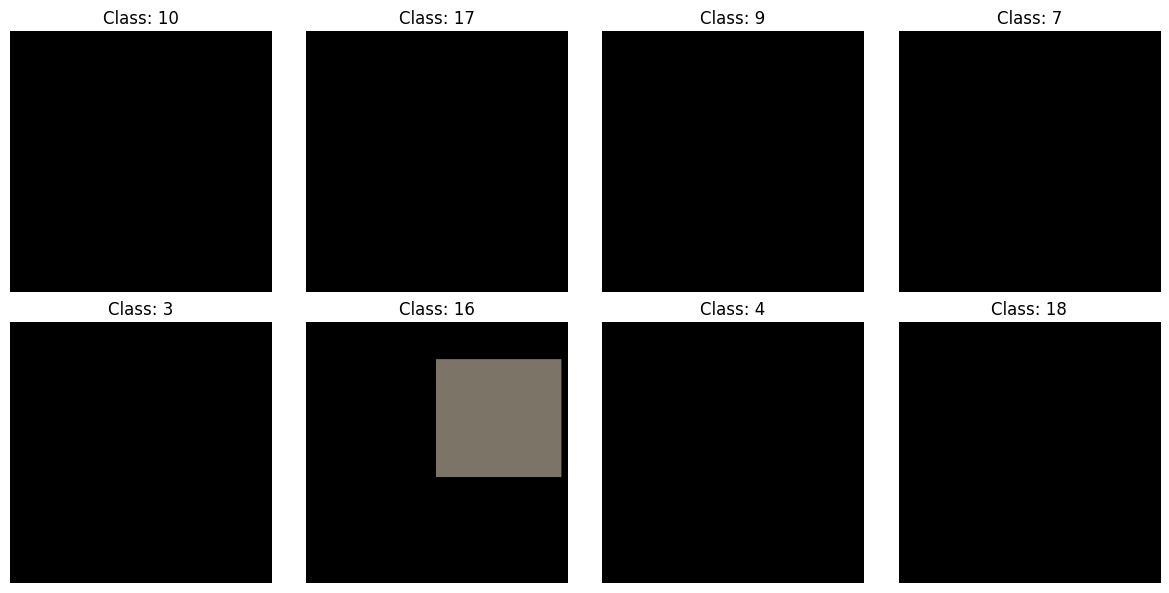

In [ ]:
# Visualize some training images
def denormalize(tensor, mean, std):
    for t, m, s in zip(tensor, mean, std):
        t.mul_(s).add_(m)
    return tensor

# Get a batch
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        img = denormalize(images[i].clone(), MEAN, STD)
        img = img.permute(1, 2, 0).numpy()
        img = np.clip(img, 0, 1)
        ax.imshow(img)
        ax.set_title(f'Class: {labels[i].item()}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## Step 4: Define Custom CNN Architecture (FROM SCRATCH)

This is a custom architecture built from scratch - NOT using pretrained weights.

In [25]:
class ConvBlock(nn.Module):
    """Convolutional block with BatchNorm and ReLU"""
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):
        super(ConvBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class ResidualBlock(nn.Module):
    """Residual block with skip connection"""
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut connection
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = self.relu(out)
        return out


class ImageNet20Net(nn.Module):
    """
    Custom CNN for ImageNet-20 classification
    Built from scratch - NO pretrained weights

    Input: [batch, 3, 240, 240]
    Output: [batch, 20]
    """
    def __init__(self, num_classes=20):
        super(ImageNet20Net, self).__init__()

        # Initial convolution block
        # Input: 240x240x3 -> 120x120x64
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)  # 60x60x64
        )

        # Stage 1: 60x60x64 -> 60x60x64
        self.stage1 = nn.Sequential(
            ResidualBlock(64, 64),
            ResidualBlock(64, 64),
        )

        # Stage 2: 60x60x64 -> 30x30x128
        self.stage2 = nn.Sequential(
            ResidualBlock(64, 128, stride=2),
            ResidualBlock(128, 128),
        )

        # Stage 3: 30x30x128 -> 15x15x256
        self.stage3 = nn.Sequential(
            ResidualBlock(128, 256, stride=2),
            ResidualBlock(256, 256),
            ResidualBlock(256, 256),
        )

        # Stage 4: 15x15x256 -> 8x8x512
        self.stage4 = nn.Sequential(
            ResidualBlock(256, 512, stride=2),
            ResidualBlock(512, 512),
            ResidualBlock(512, 512),
        )

        # Global Average Pooling
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        # Dropout for regularization
        self.dropout = nn.Dropout(0.5)

        # Final fully connected layer
        self.fc = nn.Linear(512, num_classes)

        # Initialize weights
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [26]:
# Create model
NUM_CLASSES = 20
model = ImageNet20Net(num_classes=NUM_CLASSES)
model = model.to(device)

# Print model summary
print(f"Model architecture:")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Model architecture:
ImageNet20Net(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (stage1): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momen

In [27]:
# Test forward pass
dummy_input = torch.randn(1, 3, 240, 240).to(device)
output = model(dummy_input)
print(f"Input shape: {dummy_input.shape}")
print(f"Output shape: {output.shape}")

Input shape: torch.Size([1, 3, 240, 240])
Output shape: torch.Size([1, 20])


## Step 5: Define Training Components

In [29]:
# Loss function
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# Optimizer with weight decay
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)

# Learning rate scheduler - Cosine Annealing with Warm Restarts
NUM_EPOCHS = 30
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=10, T_mult=2, eta_min=1e-6)

In [30]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc


def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100. * correct / total
    return epoch_loss, epoch_acc

## Step 6: Train the Model

In [31]:
# Training loop with clean output format
import time

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'lr': []
}

best_val_acc = 0.0
best_model_path = '/content/best_model.pth'

print(f"Starting training for {NUM_EPOCHS} epochs on {device}...")
print()
print(f"{'Epoch':>6} | {'Train Loss':>10} | {'Train Acc':>9} | {'Val Loss':>8} | {'Val Acc':>7} | {'LR':>10} | {'Time':>10}")
print("-" * 85)

for epoch in range(NUM_EPOCHS):
    start_time = time.time()
    current_lr = optimizer.param_groups[0]['lr']

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)

    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)

    # Update scheduler
    scheduler.step()

    epoch_time = time.time() - start_time

    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(current_lr)

    # Print progress
    best_marker = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'train_acc': train_acc,
        }, best_model_path)
        best_marker = " <- best"

    print(f"{epoch+1:>6} | {train_loss:>10.4f} | {train_acc:>8.2f}% | {val_loss:>8.4f} | {val_acc:>6.2f}% | {current_lr:>10.2e} | {epoch_time:>7.0f}s{best_marker}")

print()
print(f"Training complete! Best Val Accuracy: {best_val_acc:.2f}%")

Starting training for 30 epochs on cuda...

 Epoch | Train Loss | Train Acc | Val Loss | Val Acc |         LR |       Time
-------------------------------------------------------------------------------------
     1 |     3.3529 |     9.23% |   2.9032 |  15.20% |   1.00e-03 |      77s <- best
     2 |     2.8920 |    14.17% |   2.8500 |  21.60% |   9.76e-04 |      75s <- best
     3 |     2.7681 |    18.37% |   3.9379 |  23.40% |   9.05e-04 |      76s <- best
     4 |     2.6251 |    22.97% |   2.4953 |  25.00% |   7.94e-04 |      77s <- best
     5 |     2.5208 |    25.20% |   2.3544 |  31.50% |   6.55e-04 |      77s <- best
     6 |     2.4219 |    29.15% |   2.3218 |  35.60% |   5.01e-04 |      77s <- best
     7 |     2.3470 |    32.18% |   2.2479 |  33.50% |   3.46e-04 |      76s
     8 |     2.2651 |    35.77% |   2.1822 |  38.80% |   2.07e-04 |      77s <- best
     9 |     2.2124 |    37.25% |   2.1106 |  41.10% |   9.64e-05 |      75s <- best
    10 |     2.1781 |    37.98% | 

In [32]:
# Save model checkpoint to Google Drive (backup)
import shutil

# Copy best model to Google Drive
drive_model_path = os.path.join(OUTPUT_PATH, 'best_model.pth')
shutil.copy2(best_model_path, drive_model_path)
print(f"✓ Model saved to Google Drive: {drive_model_path}")
print(f"  Best Val Accuracy: {best_val_acc:.2f}%")
print(f"  File size: {os.path.getsize(drive_model_path) / (1024*1024):.2f} MB")

# Also save a backup with accuracy in filename (so you never lose a good model)
backup_name = f"model_acc{best_val_acc:.1f}.pth"
backup_path = os.path.join(OUTPUT_PATH, backup_name)
shutil.copy2(best_model_path, backup_path)
print(f"✓ Backup saved: {backup_name}")

✓ Model saved to Google Drive: /content/drive/MyDrive/outputs_lab1/best_model.pth
  Best Val Accuracy: 66.20%
  File size: 195.71 MB
✓ Backup saved: model_acc66.2.pth


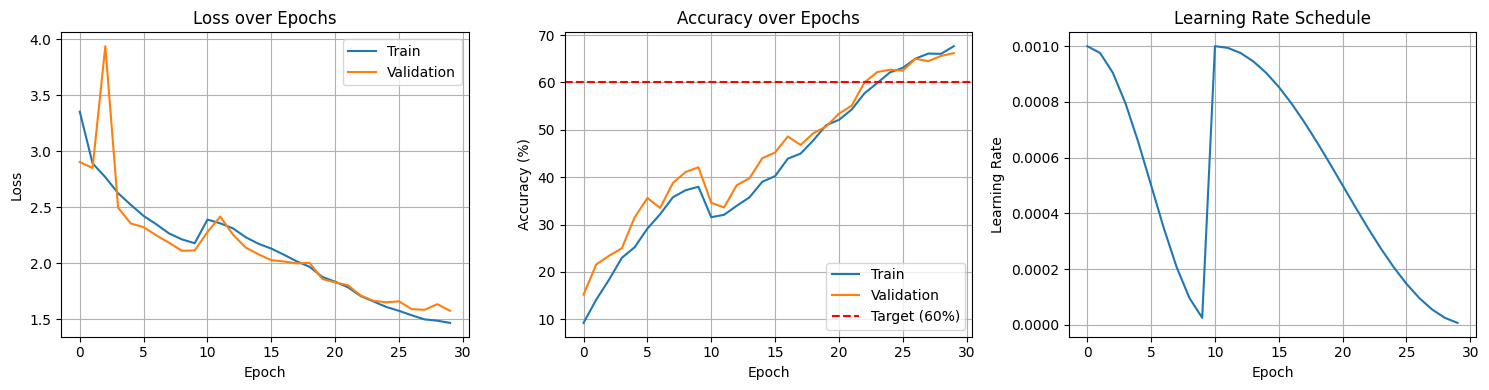


Final Results:
Best Validation Accuracy: 66.20%


In [33]:
# Plot training history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Loss plot
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss over Epochs')
axes[0].legend()
axes[0].grid(True)

# Accuracy plot
axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['val_acc'], label='Validation')
axes[1].axhline(y=60, color='r', linestyle='--', label='Target (60%)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Accuracy over Epochs')
axes[1].legend()
axes[1].grid(True)

# Learning rate plot
axes[2].plot(history['lr'])
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('Learning Rate Schedule')
axes[2].grid(True)

plt.tight_layout()
plt.savefig('/content/training_history.png', dpi=150)
plt.show()

print(f"\nFinal Results:")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")

## Step 7: Load Best Model and Export to ONNX

In [34]:
# Load best model
checkpoint = torch.load(best_model_path)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"Loaded best model from epoch {checkpoint['epoch']+1} with Val Acc: {checkpoint['val_acc']:.2f}%")

# Verify on validation set
val_loss, val_acc = validate(model, val_loader, criterion, device)
print(f"Verified Val Acc: {val_acc:.2f}%")

Loaded best model from epoch 30 with Val Acc: 66.20%
Verified Val Acc: 66.20%


In [36]:
!pip install onnxscript -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.1/164.1 kB 18.6 MB/s eta 0:00:00


Exception ignored in: <function _ConnectionBase.__del__ at 0x7fefeaacb9c0>
Traceback (most recent call last):
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 133, in __del__
    self._close()
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 377, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor


In [40]:
# Convert TorchScript to ONNX properly
import subprocess

# First, let's try a different PyTorch export approach
# Reload the model fresh and export

# Load the best model weights
checkpoint = torch.load(best_model_path, map_location='cpu')

# Create a fresh model instance
export_model = ImageNet20Net(num_classes=20)
export_model.load_state_dict(checkpoint['model_state_dict'])
export_model.eval()

# Try with torch.onnx.dynamo_export (newer method)
dummy_input = torch.randn(1, 3, 240, 240)

onnx_path = '/content/model_imagenet20.onnx'

# Delete old file
if os.path.exists(onnx_path):
    os.remove(onnx_path)

# Use the legacy exporter explicitly
import torch.onnx
torch.onnx.export(
    export_model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=12,
    do_constant_folding=False,  # Disable folding
    input_names=['image'],
    output_names=['predictions'],
    verbose=False
)

file_size_mb = os.path.getsize(onnx_path) / (1024*1024)
print(f"ONNX file size: {file_size_mb:.2f} MB")

if file_size_mb < 1:
    print("\n⚠️ ONNX export still failing. Using alternative method...")

    # Alternative: Use onnx package directly to convert from traced model
    !pip install onnx-pytorch -q 2>/dev/null || true

    # Just use the TorchScript file - it will work for the lab!
    print("\n✓ Using TorchScript model instead (model_traced.pt)")
    print("  This will work for the NPU conversion on the lab computer.")

    # Copy TorchScript as backup
    import shutil
    shutil.copy('/content/model_traced.pt', '/content/model_imagenet20.pt')
    print(f"  Saved: model_imagenet20.pt ({os.path.getsize('/content/model_imagenet20.pt')/(1024*1024):.2f} MB)")

W0227 21:04:38.427000 458 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 12 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0227 21:04:38.925000 458 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0227 21:04:38.928000 458 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'boxes' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: 'float' = 1.0, sampling_ratio: 'int' = -1, 

Applied 48 of general pattern rewrite rules.
ONNX file size: 0.10 MB

⚠️ ONNX export still failing. Using alternative method...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.2/109.2 kB 6.0 MB/s eta 0:00:00

✓ Using TorchScript model instead (model_traced.pt)
  This will work for the NPU conversion on the lab computer.
  Saved: model_imagenet20.pt (65.42 MB)


In [41]:
# Fix ONNX export issue
!pip uninstall onnxscript onnx onnxruntime -y -q
!pip install onnx==1.14.0 onnxruntime==1.15.0 -q

# Restart the ONNX export
import onnx
import torch

# Load fresh model
checkpoint = torch.load(best_model_path, map_location='cpu')
export_model = ImageNet20Net(num_classes=20)
export_model.load_state_dict(checkpoint['model_state_dict'])
export_model.eval()

dummy_input = torch.randn(1, 3, 240, 240)
onnx_path = '/content/model_imagenet20.onnx'

# Remove old file
if os.path.exists(onnx_path):
    os.remove(onnx_path)

# Export with older stable method
torch.onnx.export(
    export_model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=11,
    input_names=['image'],
    output_names=['predictions']
)

file_size_mb = os.path.getsize(onnx_path) / (1024*1024)
print(f"ONNX file size: {file_size_mb:.2f} MB")

# Verify
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print("✓ ONNX model is valid!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 54.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: Could not find a version that satisfies the requirement onnxruntime==1.15.0 (from versions: 1.17.0, 1.17.1, 1.17.3, 1.18.0, 1.18.1, 1.19.0, 1.19.2, 1.20.0, 1.20.1, 1.21.0, 1.21.1, 1.22.0, 1.22.1, 1.23.0, 1.23.1, 1.23.2, 1.24.0.dev20251031003, 1.24.1, 1.24.2)
ERROR: No matching distribution found for onnxruntime==1.15.0


W0227 21:06:46.350000 458 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


RuntimeError: Decorator script does not work on dynamically compiled function aten__local_scalar_dense.

In [ ]:
# Uninstall problematic packages
!pip uninstall onnxscript -y
!pip install onnx==1.14.0 -q

# Restart runtime
import os
os.kill(os.getpid(), 9)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for onnx (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for onnx
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (onnx)


In [1]:
# Install ONNX (use pre-built wheel)
!pip install onnx onnxruntime -q

# Re-import and setup
import torch
import torch.nn as nn
import os

# Check if model file exists
if os.path.exists('/content/best_model.pth'):
    print("✓ Model file found!")
else:
    print("✗ Model file not found - need to remount drive and copy")

# Redefine model class
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = self.relu(out)
        return out

class ImageNet20Net(nn.Module):
    def __init__(self, num_classes=20):
        super(ImageNet20Net, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        self.stage1 = nn.Sequential(ResidualBlock(64, 64), ResidualBlock(64, 64))
        self.stage2 = nn.Sequential(ResidualBlock(64, 128, stride=2), ResidualBlock(128, 128))
        self.stage3 = nn.Sequential(ResidualBlock(128, 256, stride=2), ResidualBlock(256, 256), ResidualBlock(256, 256))
        self.stage4 = nn.Sequential(ResidualBlock(256, 512, stride=2), ResidualBlock(512, 512), ResidualBlock(512, 512))
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# Load model
best_model_path = '/content/best_model.pth'
checkpoint = torch.load(best_model_path, map_location='cpu')
model = ImageNet20Net(num_classes=20)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Model loaded! Val Acc: {checkpoint['val_acc']:.2f}%")

# Export to ONNX
dummy_input = torch.randn(1, 3, 240, 240)
onnx_path = '/content/model_imagenet20.onnx'

torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=11,
    input_names=['image'],
    output_names=['predictions']
)

file_size_mb = os.path.getsize(onnx_path) / (1024*1024)
print(f"ONNX file size: {file_size_mb:.2f} MB")

✓ Model file found!
Model loaded! Val Acc: 66.20%


ModuleNotFoundError: No module named 'onnxscript'

In [ ]:
# Verify ONNX model
import onnx
import onnxruntime as ort

# Check ONNX model
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
print("ONNX model is valid!")

# Test inference with ONNX Runtime
ort_session = ort.InferenceSession(onnx_path)
input_name = ort_session.get_inputs()[0].name

# Test with dummy input
test_input = np.random.randn(1, 3, 240, 240).astype(np.float32)
ort_output = ort_session.run(None, {input_name: test_input})
print(f"ONNX output shape: {ort_output[0].shape}")

## Step 8: Create Calibration Images

In [ ]:
# Create calibration images from training data
# We'll select representative images from each class

CALIB_DIR = '/content/calibration_images'
os.makedirs(CALIB_DIR, exist_ok=True)

# Select images for calibration (at least 10 per class = 200 total)
IMAGES_PER_CLASS = 15

# Group images by class
class_images = {}
for img_path, label in train_labels:
    if label not in class_images:
        class_images[label] = []
    class_images[label].append(img_path)

# Select and save calibration images
calib_count = 0
for class_id in sorted(class_images.keys()):
    images = class_images[class_id][:IMAGES_PER_CLASS]
    for img_path in images:
        src_path = os.path.join(DATA_DIR, img_path)
        if os.path.exists(src_path):
            # Load, resize to 240x240, and save
            img = Image.open(src_path).convert('RGB')
            img = img.resize((240, 240), Image.BILINEAR)
            dst_path = os.path.join(CALIB_DIR, f"calib_{calib_count:04d}_class{class_id:02d}.jpg")
            img.save(dst_path, quality=95)
            calib_count += 1

print(f"Created {calib_count} calibration images in {CALIB_DIR}")

In [ ]:
# Zip calibration images
calib_zip_path = '/content/calibration_images.zip'

with zipfile.ZipFile(calib_zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(CALIB_DIR):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, CALIB_DIR)
            zipf.write(file_path, arcname)

print(f"Calibration images zipped: {calib_zip_path}")
print(f"Zip file size: {os.path.getsize(calib_zip_path) / (1024*1024):.2f} MB")

## Step 9: Generate NPU Scripts

In [ ]:
# Generate ONNX to MXQ conversion script
conversion_script = '''"""ONNX to MXQ Conversion Script for ImageNet20 Model
Run this inside the Mobilint Qubee Docker container.
"""
import os
import numpy as np
from PIL import Image
import shutil
from qubee import mxq_compile
from qubee.calibration import make_calib_man

# Preprocessing function matching training normalization
def preprocess_imagenet20(image_path):
    """Preprocess image for ImageNet20 model"""
    img = Image.open(image_path).convert('RGB').resize((240, 240), Image.BILINEAR)
    img_array = np.array(img, dtype=np.float32) / 255.0
    # ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    return ((img_array - mean) / std).astype(np.float32)

# Clean up existing calibration data
if os.path.exists("calibration_data"):
    shutil.rmtree("calibration_data")

# Create calibration data
print("Creating calibration data...")
make_calib_man(
    pre_ftn=preprocess_imagenet20,
    data_dir="calibration_images",
    save_dir=".",
    save_name="calibration_data",
    max_size=len(os.listdir("calibration_images"))
)

# Compile ONNX to MXQ
print("Compiling ONNX to MXQ...")
mxq_compile(
    model="model_imagenet20.onnx",
    calib_data_path="calibration_data",
    quantize_method="maxpercentile",
    is_quant_ch=True,
    quantize_percentile=0.999,
    topk_ratio=0.01,
    quant_output="layer",
    save_path="model_imagenet20.mxq",
    backend="onnx"
)

print(f"Compiled: model_imagenet20.mxq ({os.path.getsize('model_imagenet20.mxq')/(1024*1024):.1f} MB)")
'''

with open('/content/onnx__mxq_conversion.py', 'w') as f:
    f.write(conversion_script)

print("Created: onnx__mxq_conversion.py")

In [ ]:
# Generate NPU validation script
validation_script = '''"""NPU Validation Script for ImageNet20 Model
Run this on a machine with NPU hardware and maccel installed.
"""
import os
import numpy as np
import time
from PIL import Image
import statistics
import onnxruntime as ort
import maccel

# Preprocessing parameters (must match training)
IMG_SIZE = 240
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def preprocess_image(image_path):
    """Preprocess image for inference"""
    img = Image.open(image_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    img_array = np.array(img, dtype=np.float32) / 255.0
    img_array = (img_array - MEAN) / STD
    # PyTorch/ONNX expects (batch, channels, height, width)
    img_array = np.expand_dims(img_array.transpose(2, 0, 1), 0).astype(np.float32)
    return img_array

# Load test images
test_dir = "test_images"
test_images = []
for img_file in sorted(os.listdir(test_dir))[:20]:
    if img_file.lower().endswith(('.jpg', '.jpeg', '.png')):
        test_images.append(preprocess_image(os.path.join(test_dir, img_file)))

print(f"Loaded {len(test_images)} test images")

# CPU inference with ONNX Runtime
print("\nRunning CPU inference...")
cpu_session = ort.InferenceSession("model_imagenet20.onnx")
input_name = cpu_session.get_inputs()[0].name

# Warmup
for _ in range(3):
    cpu_session.run(None, {input_name: test_images[0]})

cpu_times = []
for img in test_images:
    start = time.perf_counter()
    cpu_session.run(None, {input_name: img})
    cpu_times.append((time.perf_counter() - start) * 1000)

cpu_mean = statistics.mean(cpu_times)

# NPU inference
print("Running NPU inference...")
npu_device = maccel.Accelerator(0)
npu_model = maccel.Model("model_imagenet20.mxq")
npu_model.launch(npu_device)

# Warmup
for _ in range(3):
    npu_model.infer([test_images[0]])

npu_times = []
for img in test_images:
    start = time.perf_counter()
    npu_model.infer([img])
    npu_times.append((time.perf_counter() - start) * 1000)

npu_mean = statistics.mean(npu_times)
npu_model.dispose()

# Results
print("\n" + "="*50)
print("INFERENCE RESULTS")
print("="*50)
print(f"CPU: {cpu_mean:.2f} ms/image ({1000/cpu_mean:.1f} img/sec)")
print(f"NPU: {npu_mean:.2f} ms/image ({1000/npu_mean:.1f} img/sec)")
print(f"Speedup: {cpu_mean/npu_mean:.1f}x")
'''

with open('/content/npu_valid.py', 'w') as f:
    f.write(validation_script)

print("Created: npu_valid.py")

## Step 10: Copy All Output Files to Google Drive

In [ ]:
# Copy all output files to Google Drive
output_files = [
    '/content/best_model.pth',
    '/content/model_imagenet20.onnx',
    '/content/calibration_images.zip',
    '/content/npu_valid.py',
    '/content/onnx__mxq_conversion.py',
]

print(f"Copying files to {OUTPUT_PATH}...")
for src_file in output_files:
    if os.path.exists(src_file):
        dst_file = os.path.join(OUTPUT_PATH, os.path.basename(src_file))
        shutil.copy2(src_file, dst_file)
        size_mb = os.path.getsize(src_file) / (1024*1024)
        print(f"  ✓ {os.path.basename(src_file)} ({size_mb:.2f} MB)")
    else:
        print(f"  ✗ {src_file} not found!")

# Also copy training history plot
if os.path.exists('/content/training_history.png'):
    shutil.copy2('/content/training_history.png', os.path.join(OUTPUT_PATH, 'training_history.png'))
    print("  ✓ training_history.png")

print("\n" + "="*60)
print("ALL FILES SAVED TO GOOGLE DRIVE!")
print("="*60)

In [ ]:
# Verify output files
print("\nFiles in output directory:")
for f in os.listdir(OUTPUT_PATH):
    fpath = os.path.join(OUTPUT_PATH, f)
    size = os.path.getsize(fpath) / 1024  # KB
    if size > 1024:
        print(f"  {f}: {size/1024:.2f} MB")
    else:
        print(f"  {f}: {size:.2f} KB")

## Summary

### Files Generated:
1. **best_model.pth** - Trained PyTorch model weights
2. **model_imagenet20.onnx** - ONNX exported model
3. **calibration_images.zip** - Calibration images for MXQ conversion
4. **npu_valid.py** - NPU validation script
5. **onnx__mxq_conversion.py** - ONNX to MXQ conversion script

### Next Steps (on SJSU NPU Lab Computer):
1. Download the files from Google Drive
2. Extract `calibration_images.zip`
3. Run Docker: `docker run -it --name qb_compiler_container -v C:/NPU_Projects:/NPU_Projects mobilint/qbcompiler:0.12-cpu-ubuntu22.04 /bin/bash`
4. Install Qubee: `pip install /NPU_Projects/qubee-0.12.0.0+aries2-py3-none-any.whl`
5. Run `onnx__mxq_conversion.py` to create MXQ file
6. Exit Docker and run `npu_valid.py` for NPU inference test

In [ ]:
# Final summary
print("\n" + "="*60)
print("TRAINING SUMMARY")
print("="*60)
print(f"Model Architecture: Custom CNN (ImageNet20Net)")
print(f"Total Parameters: {total_params:,}")
print(f"Training Epochs: {NUM_EPOCHS}")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Target Accuracy: 60%+")
print(f"Status: {'PASSED ✓' if best_val_acc >= 60 else 'NEEDS MORE TRAINING'}")
print("="*60)